In [1]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from collections import Counter
import random

from gensim.models import KeyedVectors

In [2]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [3]:
MIN_FREQ = 2

MAX_LEN = 64
BATCH_SIZE = 64
EMBEDDING_DIM = 300
HIDDEN_DIM = 128
NUM_LAYERS = 2
DROPOUT = 0.5
NUM_CLASSES = 6
LEARNING_RATE = 1e-3
NUM_EPOCHS = 20
PATIENCE = 3

In [4]:
data_path = Path("../data/processed")

df = pd.read_csv(data_path / "tweets_lstm.csv")

print(df.shape)
df.head()

(47435, 6)


,tweet,sentiment,clean_tfidf,clean_lstm,clean_transformer,tweet_length
0,"In other words #katandandre, your food was cra...",not_cyberbullying,in other words katandandre your food was crapi...,"in other words katandandre, your food was crap...","In other words #katandandre, your food was cra...",9
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying,why is aussietv so white mkr theblock imaceleb...,why is aussietv so white? mkr theblock imacele...,Why is #aussietv so white? #MKR #theblock #ImA...,14
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying,a classy whore or more red velvet cupcakes,a classy whore? or more red velvet cupcakes?,@XochitlSuckkks a classy whore? Or more red ve...,8
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying,meh p thanks for the heads up but not too conc...,"meh. :p thanks for the heads up, but not too c...","@Jason_Gio meh. :P thanks for the heads up, bu...",17
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying,this is an isis account pretending to be a kur...,this is an isis account pretending to be a kur...,@RudhoeEnglish This is an ISIS account pretend...,17


In [5]:
label2id = {
    "religion": 0,
    "age": 1,
    "ethnicity": 2,
    "gender": 3,
    "other_cyberbullying": 4,
    "not_cyberbullying": 5
}

df["label"] = df["sentiment"].map(label2id)

print(df["sentiment"].value_counts())
print(df["label"].value_counts())

sentiment
religion               7997
age                    7992
ethnicity              7958
gender                 7932
not_cyberbullying      7859
other_cyberbullying    7697
Name: count, dtype: int64
label
0    7997
1    7992
2    7958
3    7932
5    7859
4    7697
Name: count, dtype: int64


In [6]:
X = df["clean_lstm"]
y = df["label"]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=y_train_val
)

print(f"Training set size: {len(X_train)}")
print(f"Validation set size: {len(X_val)}")
print(f"Test set size: {len(X_test)}")

Training set size: 30358
Validation set size: 7590
Test set size: 9487


Implementing the tokenization pipeline from scratch, which includes building the vocabulary from the training data, assigning unique integer IDs to words, handling unseen words with <UNK> token, and then converting variable length text sequences into fixed length inputs suitable for LSTMs.

In [7]:
counter = Counter()

for tweet in X_train:
    counter.update(tweet.split())

print(counter.most_common(20))

[('the', 19470), ('a', 15769), ('to', 14807), ('and', 13746), ('i', 13020), ('you', 11047), ('of', 9770), ('in', 9357), ('is', 8869), ('that', 7060), ('are', 5671), ('for', 5496), ('school', 4560), ('not', 4514), ('it', 4385), ('my', 4300), ('was', 4201), ('me', 4192), ('but', 3900), ('on', 3866)]


In [8]:
word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, freq in counter.items():
    if freq >= MIN_FREQ:
        word2idx[word] = len(word2idx)

print(f"Vocabulary size: {len(word2idx)}")
list(word2idx.items())[:10]

Vocabulary size: 22464


[('<PAD>', 0),
 ('<UNK>', 1),
 ('lol', 2),
 ('what', 3),
 ('?', 4),
 ('you', 5),
 ('have', 6),
 ('no', 7),
 ('idea', 8),
 ('about', 9)]

In [9]:
idx2word = {idx: word for word, idx in word2idx.items()}

Numericalizing the text

In [10]:
model_path = Path("../models/bilstm/")

joblib.dump(word2idx, model_path / "word2idx.pkl")

joblib.dump(idx2word, model_path / "idx2word.pkl")

['../models/bilstm/idx2word.pkl']

In [11]:
def numericalize(text: str) -> list[int]:
    return [
        word2idx.get(word, word2idx["<UNK>"])
        for word in text.split()
    ]

sample = X_train.iloc[0]
print(sample)
print(numericalize(sample))

lol what ? you have no idea about the spread of islam. muslims fought wars. and people die in wars. they are not called genocides. genocide is a legal term. u r an idiot who doesn't know what he is talking about see what michael the syrian sais after 500 years of muslim rule
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 16, 21, 22, 23, 24, 1, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 3, 37, 26, 38, 9, 39, 3, 40, 10, 41, 1, 42, 43, 44, 12, 45, 46]


In [12]:
X_train_ids = [numericalize(tweet) for tweet in X_train]
X_val_ids = [numericalize(tweet) for tweet in X_val]

train_lengths = [len(seq) for seq in X_train_ids]

print(pd.Series(train_lengths).describe())
print(pd.Series(train_lengths).quantile([0.90, 0.95, 0.99, 0.995, 0.999]))

count    30358.00000
mean        23.28098
std         15.28589
min          1.00000
25%         12.00000
50%         20.00000
75%         32.00000
max        650.00000
dtype: float64
0.900    47.0
0.950    51.0
0.990    55.0
0.995    57.0
0.999    61.0
dtype: float64


We can see here that 99.9% of the tweets have length <= 64, so we use MAX_LEN = 64.

In [13]:
def pad_sequence(sequence, max_len=MAX_LEN):
    if len(sequence) > max_len:
        return sequence[:max_len]

    return sequence + [word2idx["<PAD>"]] * (max_len - len(sequence))

X_train_padded = [pad_sequence(seq) for seq in X_train_ids]
X_val_padded = [pad_sequence(seq) for seq in X_val_ids]

print(len(X_train_padded[0]))
print(len(X_val_padded[0]))

64
64


Creating a PyTorch Dataset and Dataloader

In [14]:
class TweetDataset(Dataset):
    
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y.values, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TweetDataset(X_train_padded, y_train)
val_dataset = TweetDataset(X_val_padded, y_val)

print(len(train_dataset))
print(len(val_dataset))

30358
7590


In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

X_batch, y_batch = next(iter(train_loader))

print(X_batch.shape)
print(y_batch.shape)

print(X_batch.dtype)
print(y_batch.dtype)

print(X_batch[0])
print(y_batch[0])

torch.Size([64, 64])
torch.Size([64])
torch.int64
torch.int64
tensor([  281,   263,   381,  6086, 19835,    48, 13865,  6548,    10,  9439,
        19315, 15662,   112, 12306,    10,  5894,   533,   142,  1733,     1,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0])
tensor(4)


Word2Vec Embeddings - The padded sequences currently contain integer word IDs, which carry no semantic meaning by themselves, Word2Vec learns a dense vector representation for each word such that words appearing in similar contexts have similar embeddings. These pretrained embeddings are used to initialize the embedding layer of the BiLSTM which allows the model to start from meaningful semantic representations instead of learning from scratch.

In [16]:
data_path = Path("../data")

word2vec_path = (data_path / "embeddings" / "word2vec-google-news-300" / "word2vec-google-news-300.model")

word2vec = KeyedVectors.load(str(word2vec_path))

print(word2vec.vector_size)

300


In [17]:
print(word2vec["car"][:10])
print(word2vec["automobile"][:10])
print(word2vec["pizza"][:10])

print(word2vec.similarity("car", "automobile"))
print(word2vec.similarity("car", "pizza"))
print(word2vec.similarity("king", "queen"))

print(word2vec.most_similar("hate", topn=10))

[ 0.13085938  0.00842285  0.03344727 -0.05883789  0.04003906 -0.14257812
  0.04931641 -0.16894531  0.20898438  0.11962891]
[ 0.13183594  0.06054688  0.01544189  0.13476562 -0.06030273  0.06884766
  0.08837891 -0.17871094  0.2578125   0.09765625]
[-1.2597656e-01  2.5390625e-02  1.6699219e-01  5.5078125e-01
 -7.6660156e-02  1.2890625e-01  1.0253906e-01 -3.9482117e-04
  1.2158203e-01  4.3212891e-02]
0.5838368
0.23794846
0.6510956
[('despise', 0.6712517142295837), ('Hate', 0.6400400996208191), ('detest', 0.6179037094116211), ('hatred', 0.6156139969825745), ('hating', 0.6103581190109253), ('hates', 0.6091769933700562), ('HATE', 0.6020098328590393), ('dislike', 0.6013235449790955), ('love', 0.600395679473877), ('hated', 0.5922116637229919)]


In [18]:
word2vec_embedding_matrix = np.random.normal(
    loc=0,
    scale=0.6,
    size=(len(word2idx), EMBEDDING_DIM)
)

print(word2vec_embedding_matrix.shape)

(22464, 300)


In [19]:
word2vec_embedding_matrix[word2idx["<PAD>"]] = np.zeros(EMBEDDING_DIM)

found = 0

for word, idx in word2idx.items():
    if word in word2vec:
        word2vec_embedding_matrix[idx] = word2vec[word]
        found += 1

print(f"Found {found/len(word2idx)*100}% pretrained embeddings.")

word2vec_embedding_matrix = torch.tensor(
    word2vec_embedding_matrix,
    dtype=torch.float32
)

Found 54.21118233618234% pretrained embeddings.


Approximately 54% of the vocabulary was covered by the pretrained Google News Word2Vec embeddings, words not present in the pretrained vocabulary, which are primarily Twitter slangs, misspellings, hashtags and rare abusive terms were initialized randomly and learned during BiLSTM training.
Checking the output shape for a sample processed by the embedding layer.

In [20]:
embedding = nn.Embedding.from_pretrained(
    word2vec_embedding_matrix,
    freeze=False,
    padding_idx=word2idx["<PAD>"]
)

sample = X_batch[0].unsqueeze(0) # Adds a batch dimension at the front, (64,) -> (1, 64)
embedded = embedding(sample)

print(sample.shape)
print(embedded.shape)

torch.Size([1, 64])
torch.Size([1, 64, 300])


BiLSTM Classifier - The model consists of a pretrained Word2Vec embedding layer followed by a bidirectional LSTM, the final forward and backward hidden states from the last LSTM layer are concatenated, regularised using dropout, and passed through a fully connected layer to produce logits for the six cyberbullying classes.

In [21]:
class BiLSTMClassifier(nn.Module):
    
    def __init__(self, embedding_matrix):

        super().__init__()

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=False,
            padding_idx=word2idx["<PAD>"]
        )

        self.lstm = nn.LSTM(
            input_size=EMBEDDING_DIM,
            hidden_size=HIDDEN_DIM,
            num_layers=NUM_LAYERS,
            batch_first=True,
            bidirectional=True,
            dropout=DROPOUT
        )

        self.dropout = nn.Dropout(DROPOUT)

        self.fc = nn.Linear(
            HIDDEN_DIM * 2,
            NUM_CLASSES
        )

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        hidden = self.dropout(hidden)
        logits = self.fc(hidden)

        return logits

model = BiLSTMClassifier(word2vec_embedding_matrix)
logits = model(X_batch)

print(logits.shape)
print(model)

torch.Size([64, 6])
BiLSTMClassifier(
  (embedding): Embedding(22464, 300, padding_idx=0)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=6, bias=True)
)


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

Using device: cpu


In [23]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {trainable_params:,}")

Trainable parameters: 7,576,326


In [24]:
model_word2vec = BiLSTMClassifier(word2vec_embedding_matrix).to(device)

criterion = nn.CrossEntropyLoss()

optimizer_word2vec = torch.optim.Adam(
    model_word2vec.parameters(),
    lr=LEARNING_RATE
)

Training and evaluation functions - the following helper functions implement one epoch of training and model evaluation, as well as the entire training loop.

In [25]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    return total_loss/len(dataloader)

def evaluate(model, dataloader, criterion, device):
    model.eval()

    total_loss = 0.0

    predictions = []
    labels = []

    with torch.no_grad():

        for X_batch, y_batch in dataloader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            total_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            predictions.extend(preds.cpu().numpy())
            labels.extend(y_batch.cpu().numpy())

    return {
        "loss": total_loss/len(dataloader),
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "classification_report": classification_report(
            labels,
            predictions
        ),
        "predictions": predictions,
        "labels": labels
    }

def train_model(model, train_loader, val_loader, criterion, optimizer, device, model_name):  
    best_val_loss = float('inf')
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": []
    }

    for epoch in range(NUM_EPOCHS):
        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_metrics = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_macro_f1"].append(val_metrics["macro_f1"])

        print(f"Epoch {epoch+1}")
        print(f"Train loss: {train_loss:.4f}")
        print(f"Validation loss: {val_metrics['loss']:.4f}")
        print(f"Accuracy: {val_metrics['accuracy']:.4f}")
        print(f"Macro f1: {val_metrics['macro_f1']:.4f}")
        print()

        if val_metrics['loss'] < best_val_loss:
            best_val_loss = val_metrics['loss']
            patience_counter = 0

            torch.save(
                model.state_dict(),
                f"../models/bilstm/{model_name}.pth"
            )

            print(f"Validation loss improved to {best_val_loss:.4f}. Model saved.")
            print()

        else:
            patience_counter += 1
            print(f"No improvement {patience_counter}")
            print()

            if patience_counter >= PATIENCE:
                print("Early stopping.")
                break
    
    model.load_state_dict(
        torch.load(
            f"../models/bilstm/{model_name}.pth",
            map_location=device
        )
    )

    return model, history

model_word2vec, model_word2vec_history = train_model(
    model=model_word2vec,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_word2vec,
    device=device,
    model_name="bilstm_word2vec"
)

Epoch 1
Train loss: 0.7827
Validation loss: 0.4860
Accuracy: 0.8004
Macro f1: 0.7897

Validation loss improved to 0.4860. Model saved.

Epoch 2
Train loss: 0.4444
Validation loss: 0.4507
Accuracy: 0.8140
Macro f1: 0.8123

Validation loss improved to 0.4507. Model saved.

Epoch 3
Train loss: 0.3382
Validation loss: 0.4726
Accuracy: 0.8173
Macro f1: 0.8160

No improvement 1

Epoch 4
Train loss: 0.2653
Validation loss: 0.5027
Accuracy: 0.8036
Macro f1: 0.8023

No improvement 2

Epoch 5
Train loss: 0.2062
Validation loss: 0.6643
Accuracy: 0.8020
Macro f1: 0.7979

No improvement 3

Early stopping.


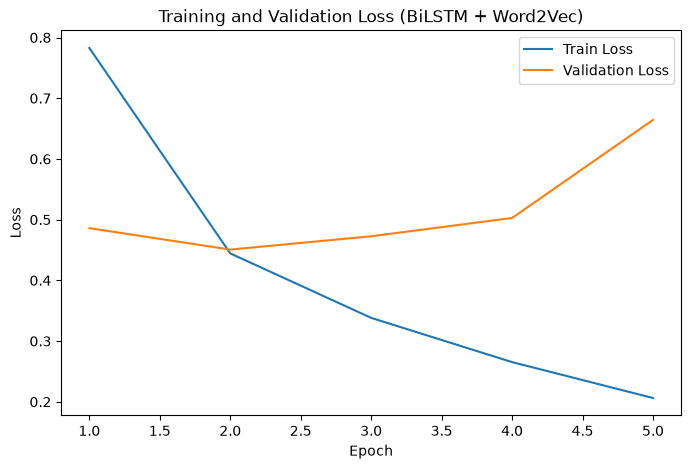

In [26]:
epochs = range(1, len(model_word2vec_history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    model_word2vec_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    model_word2vec_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss (BiLSTM + Word2Vec)")
plt.legend()

plt.show()

In [27]:
model_word2vec.load_state_dict(
    torch.load("../models/bilstm/bilstm_word2vec.pth")
)

X_test_ids = [numericalize(tweet) for tweet in X_test]
X_test_padded = [pad_sequence(seq) for seq in X_test_ids]

test_dataset = TweetDataset(X_test_padded, y_test)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_metrics_word2vec = evaluate(
    model_word2vec,
    test_loader,
    criterion,
    device
)

print(test_metrics_word2vec["classification_report"])

              precision    recall  f1-score   support

           0       0.91      0.95      0.93      1599
           1       0.96      0.97      0.97      1598
           2       0.98      0.94      0.96      1592
           3       0.89      0.81      0.85      1586
           4       0.57      0.70      0.63      1540
           5       0.60      0.51      0.55      1572

    accuracy                           0.82      9487
   macro avg       0.82      0.81      0.81      9487
weighted avg       0.82      0.82      0.82      9487



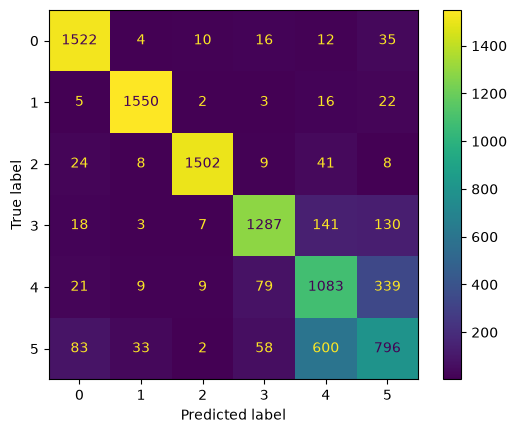

In [28]:
ConfusionMatrixDisplay.from_predictions(
    test_metrics_word2vec["labels"],
    test_metrics_word2vec["predictions"]
)

Now using GloVe embeddings instead of the Word2Vec embeddings with BiLSTM and checking if there is any improvement in the model performance.

In [29]:
glove_path = word2vec_path = (data_path / "embeddings" / "glove" / "glove.6B.300d.txt")

glove = {}

with open(glove_path, "r", encoding="utf8") as f:
    for line in f:
        values = line.rstrip().split()

        word = values[0]
        vector = np.asarray(values[1:], dtype=np.float32)

        glove[word] = vector

print(f"Loaded {len(glove):,} GloVe vectors.")
print(glove["king"][:10])

Loaded 400,000 GloVe vectors.
[ 0.0033901 -0.34614    0.28144    0.48382    0.59469    0.012965
  0.53982    0.48233    0.21463   -1.0249   ]


In [30]:
glove_embedding_matrix = np.random.normal(
    loc=0,
    scale=0.6,
    size=(len(word2idx), EMBEDDING_DIM)
)

print(f"Shape of embedding matrix: {glove_embedding_matrix.shape}")

glove_embedding_matrix[word2idx["<PAD>"]] = np.zeros(EMBEDDING_DIM)

found = 0

for word, idx in word2idx.items():
    if word in glove:
        glove_embedding_matrix[idx] = glove[word]
        found += 1

print(f"Found {found/len(word2idx)*100}% pretrained embeddings.")

glove_embedding_matrix = torch.tensor(
    glove_embedding_matrix,
    dtype=torch.float32
)

Shape of embedding matrix: (22464, 300)
Found 56.68180199430199% pretrained embeddings.


In [31]:
model_glove = BiLSTMClassifier(glove_embedding_matrix).to(device)

optimizer_glove = torch.optim.AdamW(
    model_glove.parameters(),
    lr=LEARNING_RATE
)

model_glove, model_glove_history = train_model(
    model=model_glove,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_glove,
    device=device,
    model_name="bilstm_glove"
)

Epoch 1
Train loss: 0.7356
Validation loss: 0.4860
Accuracy: 0.7843
Macro f1: 0.7862

Validation loss improved to 0.4860. Model saved.

Epoch 2
Train loss: 0.4342
Validation loss: 0.4285
Accuracy: 0.8220
Macro f1: 0.8197

Validation loss improved to 0.4285. Model saved.

Epoch 3
Train loss: 0.3312
Validation loss: 0.4381
Accuracy: 0.8253
Macro f1: 0.8230

No improvement 1

Epoch 4
Train loss: 0.2556
Validation loss: 0.4971
Accuracy: 0.8153
Macro f1: 0.8134

No improvement 2

Epoch 5
Train loss: 0.2004
Validation loss: 0.5297
Accuracy: 0.8057
Macro f1: 0.8079

No improvement 3

Early stopping.


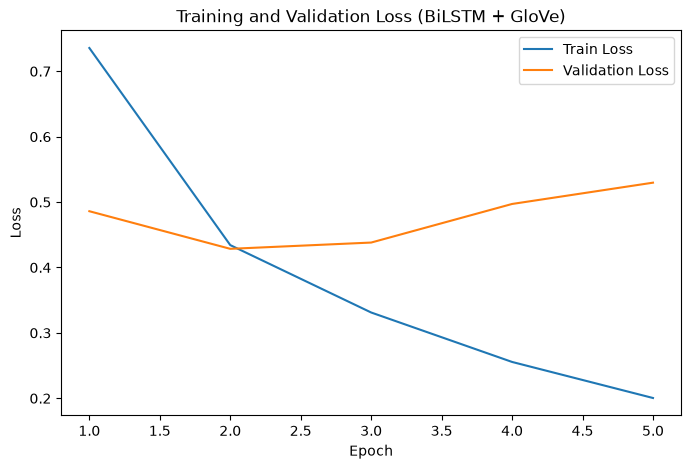

In [32]:
epochs = range(1, len(model_glove_history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    model_glove_history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    model_glove_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss (BiLSTM + GloVe)")
plt.legend()

plt.show()

In [33]:
model_glove.load_state_dict(
    torch.load("../models/bilstm/bilstm_glove.pth")
)

test_metrics_glove = evaluate(
    model_glove,
    test_loader,
    criterion,
    device
)

print(test_metrics_glove["classification_report"])

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      1599
           1       0.97      0.96      0.96      1598
           2       0.98      0.96      0.97      1592
           3       0.89      0.83      0.86      1586
           4       0.59      0.80      0.68      1540
           5       0.64      0.47      0.54      1572

    accuracy                           0.83      9487
   macro avg       0.83      0.83      0.83      9487
weighted avg       0.84      0.83      0.83      9487



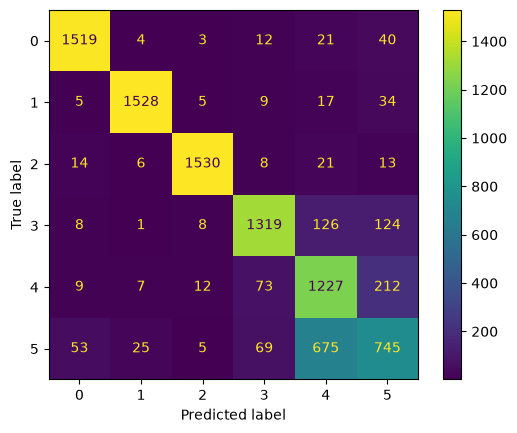

In [34]:
ConfusionMatrixDisplay.from_predictions(
    test_metrics_glove["labels"],
    test_metrics_glove["predictions"]
)

In [35]:
id2label = {v: k for k, v in label2id.items()}

report_word2vec = classification_report(
    test_metrics_word2vec["labels"],
    test_metrics_word2vec["predictions"],
    output_dict=True,
    zero_division=0
)

report_glove = classification_report(
    test_metrics_glove["labels"],
    test_metrics_glove["predictions"],
    output_dict=True,
    zero_division=0
)

rows = []

for label_id in sorted(label2id.values()):

    w2v = report_word2vec[str(label_id)]
    glove = report_glove[str(label_id)]

    rows.append({
        "Class": id2label[label_id],

        "W2V Precision": round(w2v["precision"], 3),
        "GloVe Precision": round(glove["precision"], 3),

        "W2V Recall": round(w2v["recall"], 3),
        "GloVe Recall": round(glove["recall"], 3),

        "W2V F1": round(w2v["f1-score"], 3),
        "GloVe F1": round(glove["f1-score"], 3),

        "Delta F1": round(glove["f1-score"] - w2v["f1-score"], 3),

        "Winner": (
            "GloVe"
            if glove["f1-score"] > w2v["f1-score"]
            else "Word2Vec"
        ),

        "Support": int(w2v["support"])
    })

comparison_df = pd.DataFrame(rows)

comparison_df

,Class,W2V Precision,GloVe Precision,W2V Recall,GloVe Recall,W2V F1,GloVe F1,Delta F1,Winner,Support
0,religion,0.910,0.945,0.952,0.950,0.930,0.947,0.017,GloVe,1599
1,age,0.965,0.973,0.970,0.956,0.967,0.964,-0.003,Word2Vec,1598
2,ethnicity,0.980,0.979,0.943,0.961,0.962,0.970,0.008,GloVe,1592
3,gender,0.886,0.885,0.811,0.832,0.847,0.858,0.010,GloVe,1586
4,other_cyberbullying,0.572,0.588,0.703,0.797,0.631,0.677,0.046,GloVe,1540
5,not_cyberbullying,0.598,0.638,0.506,0.474,0.549,0.544,-0.005,Word2Vec,1572


BiLSTM initialized with GloVe embeddings achieved better overall performance than BiLSTM initialized with Word2Vec embeddings. GloVe produced higher F1-scores on four of the six classes, with the largest improvement observed in the other_cyberbullying class. Word2Vec slightly outperformed GloVe on the ethinicity and not_cyberbullying classes, these gains were relatively smaller. Overall, GloVe provided a stronger representation for this dataset. 